# 06 · Co-12 evaluation of every explanation method

Nauta et al. (2023) reviewed how XAI methods are evaluated and grouped the desirable
properties of an explanation into **12 conceptual properties (Co-12)**:

| dimension | properties |
|---|---|
| **content** | Correctness, Completeness, Consistency, Continuity, Contrastivity, Covariate complexity |
| **presentation** | Compactness, Composition, Confidence |
| **user** | Context, Coherence, Controllability |

The original project rated seven methods on the first nine properties from the
literature. This notebook rates **all eleven methods on all twelve properties**, and
wherever possible the rating is **derived from a measurement made in notebooks 01–05**
rather than from general knowledge about the method. Every cell keeps the evidence that
produced it.

**Scale:** 0 = poor · 1 = limited · 2 = good · 3 = strong · n/a = not applicable.
Measured ratings use fixed thresholds written in the code below, so they can be
challenged and re-run.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

from tcner_xai import plotting
from tcner_xai.config import RESULTS_DIR

plotting.set_style()
R = RESULTS_DIR
bench = pd.read_csv(R / "benchmark_summary.csv")
extra = pd.read_csv(R / "benchmark_extra.csv")
stab = pd.read_csv(R / "benchmark_stability_summary.csv", index_col=0)["value"]
anch = pd.read_csv(R / "anchors_summary.csv", index_col=0)["value"]
fid = pd.read_csv(R / "surrogate_fidelity.csv")
pi = pd.read_csv(R / "global_permutation_importance.csv")
cal = pd.read_csv(R / "calibration_summary.csv", index_col=0)
agree = pd.read_csv(R / "benchmark_pairwise_agreement.csv", index_col=0)
cases = pd.read_csv(R / "case_studies.csv")


def b(method, setting, col, table=bench):
    d = table[(table["method"] == method) & (table["setting"].astype(str) == str(setting))]
    return float(d[col].iloc[0])


def rate(x, cuts, higher_is_better=True):
    """Map a measurement to 0-3 using three cut points."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    level = sum(x >= c for c in cuts) if higher_is_better else sum(x <= c for c in cuts)
    return int(level)


# On this linear model every attribution method reaches a rank correlation of >= 0.9 with
# the truth (a random ranking: ~0.0), so the cut points sit high: "+++" requires
# essentially exact agreement.
SPEARMAN_CUTS = (0.85, 0.93, 0.99)  # correctness of word rankings
STABILITY_CUTS = (0.8, 0.9, 0.99)   # seed / null-edit stability (Jaccard or Spearman)
CONSENSUS_CUTS = (0.85, 0.9, 0.95)  # mean agreement with the other explainers
WORDS_CUTS = (4.0, 3.0, 2.0)        # words needed for 80% of attribution (lower = compact)

## Measurements feeding the ratings

In [2]:
# Each sampling method is rated at (close to) its library default budget:
# LIME num_samples=5000; KernelSHAP 'auto' ≈ 2·M + 2048 → we use 1,000 (exact for ≤ 9 words).
meas = {
    "LIME": dict(method="LIME", setting=5000),
    "KernelSHAP": dict(method="KernelSHAP", setting=1000),
    "Exact Shapley": dict(method="Exact Shapley", setting="exact"),
    "Occlusion": dict(method="Occlusion", setting="n+1 calls"),
    "Linear SHAP": dict(method="Linear SHAP", setting="closed form"),
}
m = {k: {c: b(v["method"], v["setting"], c) for c in ["spearman", "agree@3", "comp@1", "words@80%"]}
     for k, v in meas.items()}
for k, v in meas.items():
    m[k].update({c: b(v["method"], v["setting"], c, extra) for c in ["efficiency_gap", "contrast_spearman"]})
m["Linear SHAP"]["absent_share"] = b("Linear SHAP", "closed form", "absent_share", extra)
m["LIME"]["lime_r2"] = b("LIME", 5000, "lime_r2", extra)
depth4 = fid[fid["max_depth"].astype(str) == "4"].iloc[0]
best_fid = fid["fidelity (test)"].max()
pi_rel_std = float((pi.head(20)["std"] / pi.head(20)["importance"]).mean())
display(pd.DataFrame(m).T.round(3))
print(stab.round(3).to_string())
print(anch.round(3).to_string())

,spearman,agree@3,comp@1,words@80%,efficiency_gap,contrast_spearman,lime_r2,absent_share
LIME,0.958,0.923,0.191,3.407,0.174,-0.704,0.852,NaN
KernelSHAP,0.999,0.999,0.190,3.492,0.000,-0.681,NaN,NaN
Exact Shapley,1.000,1.000,0.190,3.491,0.000,-0.681,NaN,NaN
Occlusion,0.897,0.856,0.192,3.278,NaN,-0.732,NaN,NaN
Linear SHAP,0.905,0.838,0.189,3.584,NaN,-0.537,NaN,0.462


LIME@64 top3 jaccard                 0.843
LIME@64 spearman                     0.921
LIME@64 rel. std                     0.154
KernelSHAP@64 top3 jaccard           0.920
KernelSHAP@64 spearman               0.960
KernelSHAP@64 rel. std               0.074
LIME@1000 top3 jaccard               0.956
LIME@1000 spearman                   0.978
LIME@1000 rel. std                   0.036
KernelSHAP@1000 top3 jaccard         0.997
KernelSHAP@1000 spearman             0.999
KernelSHAP@1000 rel. std             0.002
Exact Shapley continuity spearman    1.000
Exact Shapley null-word share        0.000
LIME continuity spearman             0.976
LIME null-word share                 0.007
KernelSHAP continuity spearman       0.997
KernelSHAP null-word share           0.001
n_words                     6.884
length                      1.233
precision                   0.999
coverage                    0.448
removal precision           0.996
test-set coverage           0.023
test-set precision    

## The Co-12 matrix

In [3]:
METHODS = ["LIME", "KernelSHAP", "Exact Shapley", "Occlusion", "Linear SHAP", "Anchors",
           "Counterfactual", "Coefficients", "Permutation imp.", "Surrogate tree", "Entropy"]
PROPS = ["Correctness", "Completeness", "Consistency", "Continuity", "Contrastivity",
         "Covariate complexity", "Compactness", "Composition", "Confidence", "Context",
         "Coherence", "Controllability"]
cells = {}


def put(prop, method, score, evidence, measured=False):
    cells[(prop, method)] = dict(score=score, evidence=evidence, measured=measured)


# ---- Correctness: faithfulness to what the model actually does ----------------------
for k in ["LIME", "KernelSHAP", "Occlusion", "Linear SHAP"]:
    put("Correctness", k, rate(m[k]["spearman"], SPEARMAN_CUTS),
        f"Spearman with exact Shapley = {m[k]['spearman']:.2f}; top-3 agreement = {m[k]['agree@3']:.2f}", True)
put("Correctness", "Exact Shapley", 3, "ground truth of the word-removal game by construction", True)
put("Correctness", "Anchors", rate(anch["test-set precision"], (0.7, 0.85, 0.95)),
    f"rule precision {anch['precision']:.2f} under alibi's sampling and {anch['removal precision']:.2f} under word "
    f"removal, but {anch['test-set precision']:.2f} on real titles containing the rule", True)
put("Correctness", "Counterfactual", 3, "every reported edit is verified to flip the prediction (exhaustive search)", True)
put("Correctness", "Coefficients", 3, "they are the model's parameters (exact global explanation)")
put("Correctness", "Permutation imp.", 3, "exact per-shuffle accuracy drop, validated against re-prediction", True)
put("Correctness", "Surrogate tree", rate(depth4["fidelity (test)"], (0.6, 0.8, 0.95)),
    f"depth-4 fidelity = {depth4['fidelity (test)']:.2f} on test titles", True)
put("Correctness", "Entropy", 3, "computed directly from the model's probabilities")

# ---- Completeness: how much of the model's reasoning is captured -------------------
put("Completeness", "Exact Shapley", 3, f"efficiency: attributions sum to P(full) − P(empty) (gap {m['Exact Shapley']['efficiency_gap']:.1e})", True)
put("Completeness", "KernelSHAP", rate(-m["KernelSHAP"]["efficiency_gap"], (-0.05, -0.02, -0.005)),
    f"efficiency enforced by the solver (mean gap {m['KernelSHAP']['efficiency_gap']:.3f})", True)
put("Completeness", "LIME", rate(m["LIME"]["lime_r2"], (0.5, 0.75, 0.95)),
    f"local surrogate R² = {m['LIME']['lime_r2']:.2f}; weights do not add up to the prediction (gap {m['LIME']['efficiency_gap']:.2f})", True)
put("Completeness", "Occlusion", 1, "one removal per word; ignores what words do together")
put("Completeness", "Linear SHAP", rate(1 - m["Linear SHAP"]["absent_share"], (0.3, 0.6, 0.9)),
    f"{m['Linear SHAP']['absent_share']:.0%} of |attribution| sits on n-grams absent from the title", True)
put("Completeness", "Anchors", rate(anch["test-set coverage"], (0.02, 0.1, 0.3)),
    f"one sufficient rule; covers {anch['test-set coverage']:.1%} of test titles on average "
    f"(alibi reports {anch['coverage']:.2f} on its own samples); contains the top Shapley word "
    f"in {anch['contains GT top word']:.0%} of cases", True)
put("Completeness", "Counterfactual", 1, "one minimal contrast per question")
put("Completeness", "Coefficients", 3, "all 5×5,000 weights fully describe the linear model")
put("Completeness", "Permutation imp.", 2, "all features, but only their effect on accuracy")
put("Completeness", "Surrogate tree", rate(best_fid, (0.6, 0.8, 0.95)),
    f"even an unlimited tree reaches only {best_fid:.2f} fidelity", True)
put("Completeness", "Entropy", 1, "says how sure, not why")

# ---- Consistency: same input, same explanation (seeds / implementations) ----------
for k in ["LIME", "KernelSHAP"]:
    put("Consistency", k, rate(stab[f"{k}@1000 top3 jaccard"], STABILITY_CUTS),
        f"top-3 Jaccard across 5 seeds = {stab[f'{k}@1000 top3 jaccard']:.2f} at 1,000 calls "
        f"({stab[f'{k}@64 top3 jaccard']:.2f} at 64)", True)
for k in ["Exact Shapley", "Occlusion", "Counterfactual", "Entropy"]:
    put("Consistency", k, 3, "deterministic")
put("Consistency", "Linear SHAP", 2, "deterministic, but depends on the background set (original: first 100 training rows)")
put("Consistency", "Anchors", rate(anch["same rule across 3 seeds"], (0.5, 0.75, 0.95)),
    f"identical rule across 3 seeds for {anch['same rule across 3 seeds']:.0%} of titles", True)
put("Consistency", "Coefficients", 3, "deterministic given the training data and seed")
put("Consistency", "Permutation imp.", rate(-pi_rel_std, (-1.0, -0.5, -0.15)),
    f"top-20 terms: mean std/importance = {pi_rel_std:.2f} over 30 repeats", True)
put("Consistency", "Surrogate tree", 2, "deterministic, but split choice is unstable under resampling")

# ---- Continuity: similar inputs, similar explanations ------------------------------
for k in ["LIME", "KernelSHAP", "Exact Shapley"]:
    put("Continuity", k, rate(stab[f"{k} continuity spearman"], STABILITY_CUTS),
        f"rank corr. after inserting an ignored stop word = {stab[f'{k} continuity spearman']:.2f}; "
        f"share on the null word = {stab[f'{k} null-word share']:.3f}", True)
put("Continuity", "Occlusion", 3, "null word gets exactly 0; other scores unchanged")
put("Continuity", "Linear SHAP", 3, "stop word leaves the TF-IDF vector unchanged")
put("Continuity", "Anchors", 1, "discrete rules can switch with a one-word change")
put("Continuity", "Counterfactual", 1, "minimal edit can jump between word sets")
put("Continuity", "Coefficients", 3, "fixed linear weights")
put("Continuity", "Permutation imp.", 2, "smooth in the data, noisy in the shuffles")
put("Continuity", "Surrogate tree", 1, "axis-aligned thresholds are discontinuous")
put("Continuity", "Entropy", 3, "smooth function of the logits")

# ---- Contrastivity: does it answer "why A rather than B"? --------------------------
for k in ["LIME", "KernelSHAP", "Exact Shapley", "Occlusion", "Linear SHAP"]:
    c = m[k]["contrast_spearman"]
    put("Contrastivity", k, 2 if c < 0 else 1,
        f"per-venue explanations available; rank corr. predicted vs runner-up venue = {c:.2f}", True)
put("Contrastivity", "Counterfactual", 3, "natively contrastive: the edit that makes it venue B")
put("Contrastivity", "Anchors", 1, "explains why A, not why not B")
put("Contrastivity", "Coefficients", 2, "per-venue weights can be compared")
put("Contrastivity", "Permutation imp.", 0, "venue-agnostic accuracy drop")
put("Contrastivity", "Surrogate tree", 1, "paths show alternatives only implicitly")
put("Contrastivity", "Entropy", 0, "no class comparison")

# ---- Covariate complexity: interactions and correlated features --------------------
put("Covariate complexity", "Exact Shapley", 2, "splits bigram interactions fairly between the two words")
put("Covariate complexity", "KernelSHAP", 2, "estimates the same interaction-aware Shapley values")
put("Covariate complexity", "LIME", 1, "additive in word presence; cannot represent bigram interactions")
put("Covariate complexity", "Occlusion", 1, "ignores interactions (removes one word at a time)")
put("Covariate complexity", "Linear SHAP", 1, "assumes independent n-grams; ignores L2 normalisation")
put("Covariate complexity", "Anchors", 2, "conjunctions of words")
put("Covariate complexity", "Counterfactual", 2, "multi-word edits")
put("Covariate complexity", "Coefficients", 1, "correlated n-grams (e.g. neural / neural network) share weight")
put("Covariate complexity", "Permutation imp.", 0, "correlated features mask each other's importance")
put("Covariate complexity", "Surrogate tree", 2, "splits encode interactions, but only a few")
put("Covariate complexity", "Entropy", np.nan, "operates on outputs only")

# ---- Compactness ---------------------------------------------------------------------
for k in ["LIME", "KernelSHAP", "Exact Shapley", "Occlusion", "Linear SHAP"]:
    put("Compactness", k, rate(m[k]["words@80%"], WORDS_CUTS, higher_is_better=False),
        f"{m[k]['words@80%']:.1f} words carry 80% of the attribution", True)
put("Compactness", "Anchors", rate(anch["length"], (3, 2, 1.5), higher_is_better=False),
    f"mean rule length {anch['length']:.1f} words", True)
cf_sizes = cases["remove to reach true venue"].replace("—", np.nan).dropna().str.count(",") + 1
put("Compactness", "Counterfactual", 3, f"case studies: {cf_sizes.mean():.1f} word(s) to remove", True)
put("Compactness", "Coefficients", 2, "readable only as top-k per venue")
put("Compactness", "Permutation imp.", 2, "one ranked list")
put("Compactness", "Surrogate tree", 1, f"depth 4 = {int(depth4['leaves'])} leaves; faithful trees need far more", True)
put("Compactness", "Entropy", 3, "one number per title")

# ---- Composition (format and structure of the presentation) -------------------------
for k, s, e in [("LIME", 2, "highlighted text + bar chart"), ("KernelSHAP", 2, "bar chart over title words"),
                ("Exact Shapley", 2, "bar chart over title words"), ("Occlusion", 2, "bar chart over title words"),
                ("Linear SHAP", 1, "force plot over n-grams incl. absent ones; easy to misread"),
                ("Anchors", 3, "if-then rule with precision"), ("Counterfactual", 3, "a natural-language edit"),
                ("Coefficients", 2, "per-venue bar charts"), ("Permutation imp.", 2, "ranked bars, no direction"),
                ("Surrogate tree", 2, "tree diagram; dense beyond depth 3"), ("Entropy", 2, "histogram / score")]:
    put("Composition", k, s, e)

# ---- Confidence: does the explanation carry uncertainty information? ---------------
put("Confidence", "LIME", 1, "only the surrogate's R²; seed variance must be estimated separately")
put("Confidence", "KernelSHAP", 1, "variance estimable by re-running; not reported by default")
put("Confidence", "Exact Shapley", 2, "no estimation error; reports P(full title)")
put("Confidence", "Occlusion", 2, "no estimation error")
put("Confidence", "Linear SHAP", 1, "no uncertainty; background-dependent")
put("Confidence", "Anchors", 3, "precision and coverage reported with every rule")
put("Confidence", "Counterfactual", 2, "reports the probability after the edit")
put("Confidence", "Coefficients", 0, "no confidence intervals")
put("Confidence", "Permutation imp.", 3, "95% intervals over 30 repeats")
put("Confidence", "Surrogate tree", 2, "leaf class proportions + measured fidelity")
ece0, ece1 = cal.loc["original", "ECE"], cal.loc["temperature scaled", "ECE"]
put("Confidence", "Entropy", rate(-ece1, (-0.1, -0.05, -0.02)),
    f"it *is* the confidence signal; ECE {ece0:.3f} → {ece1:.3f} after recalibration", True)

# ---- Context: useful for the intended user (an author choosing a venue) ------------
for k in ["LIME", "KernelSHAP", "Exact Shapley", "Occlusion"]:
    put("Context", k, 3 if k != "LIME" else 2, "scores words the author can see and edit")
put("Context", "Linear SHAP", 1, "mostly about words that are not in the title")
put("Context", "Anchors", 2, "short rule, but low coverage")
put("Context", "Counterfactual", 3, "directly actionable: what to change for another venue")
put("Context", "Coefficients", 1, "developer-facing")
put("Context", "Permutation imp.", 1, "developer-facing")
put("Context", "Surrogate tree", 1, "developer-facing; low fidelity")
put("Context", "Entropy", 2, "supports 'abstain / show a shortlist'")

# ---- Coherence: consistent with domain knowledge and with other explanations -------
for k in ["LIME", "KernelSHAP", "Occlusion", "Linear SHAP"]:
    others = agree.loc[k].drop(k).mean()
    put("Coherence", k, rate(others, CONSENSUS_CUTS), f"consensus proxy: mean rank agreement with the other explainers = {others:.2f}", True)
put("Coherence", "Exact Shapley", 2, "top words match venue topics; exposes artefacts (datum, matter)")
put("Coherence", "Anchors", 2, "rules use topical words")
put("Coherence", "Counterfactual", 2, "suggested words are venue-typical")
put("Coherence", "Coefficients", 2, "topical terms per venue, plus boilerplate artefacts")
put("Coherence", "Permutation imp.", 2, "top terms topical, a few artefacts")
put("Coherence", "Surrogate tree", 2, "splits on venue-typical words")
put("Coherence", "Entropy", 2, "confident errors are topically ambiguous titles")

# ---- Controllability: can the user steer or query the explanation? -----------------
for k, s, e in [("LIME", 1, "number of features / samples"), ("KernelSHAP", 1, "budget and background"),
                ("Exact Shapley", 1, "choice of target venue"), ("Occlusion", 0, "none"),
                ("Linear SHAP", 1, "background set"), ("Anchors", 2, "precision threshold"),
                ("Counterfactual", 3, "user chooses the target venue"), ("Coefficients", 1, "top-k"),
                ("Permutation imp.", 0, "none"), ("Surrogate tree", 2, "depth trades fidelity for readability"),
                ("Entropy", 2, "abstention threshold")]:
    put("Controllability", k, s, e)

assert len(cells) == len(PROPS) * len(METHODS), len(cells)
scores = pd.DataFrame([[cells[(p, k)]["score"] for k in METHODS] for p in PROPS], index=PROPS, columns=METHODS)
evidence = pd.DataFrame([[cells[(p, k)]["evidence"] for k in METHODS] for p in PROPS], index=PROPS, columns=METHODS)
measured = pd.DataFrame([[cells[(p, k)]["measured"] for k in METHODS] for p in PROPS], index=PROPS, columns=METHODS)
scores.to_csv(R / "co12_scores.csv")
evidence.to_csv(R / "co12_evidence.csv")
print(f"{measured.values.sum()} of {measured.size} ratings are backed by a measurement in this repo")

40 of 132 ratings are backed by a measurement in this repo


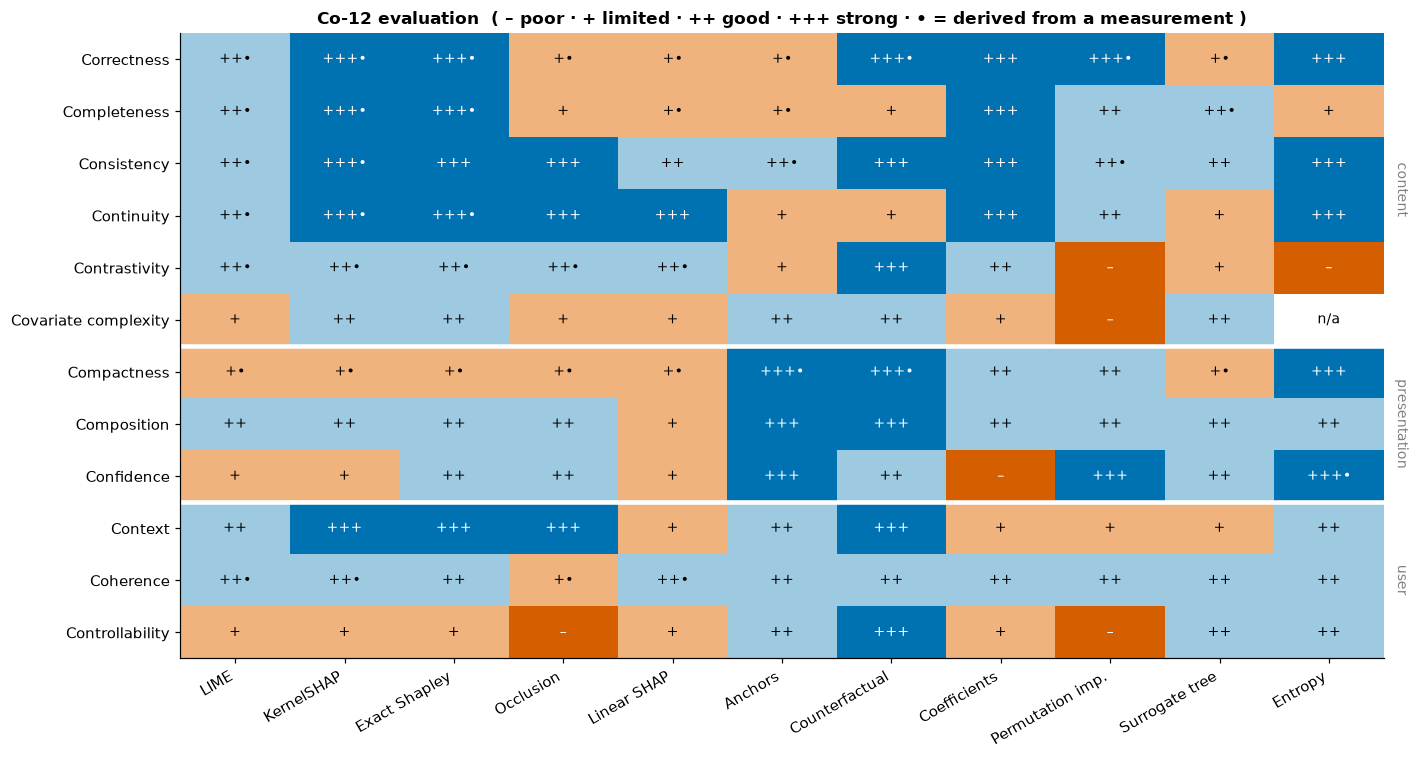

In [4]:
fig, ax = plt.subplots(figsize=(13, 7))
cmap = ListedColormap(["#D55E00", "#F0B37E", "#9ECAE1", "#0072B2"])
data = scores.values.astype(float)
ax.imshow(np.ma.masked_invalid(data), cmap=cmap, vmin=-0.5, vmax=3.5, aspect="auto")
symbols = {0: "–", 1: "+", 2: "++", 3: "+++"}
for i in range(len(PROPS)):
    for j in range(len(METHODS)):
        v = data[i, j]
        txt = "n/a" if np.isnan(v) else symbols[int(v)]
        star = "•" if measured.iloc[i, j] else ""
        ax.text(j, i, f"{txt}{star}", ha="center", va="center", fontsize=9,
                color="white" if (not np.isnan(v) and v in (0, 3)) else "black")
ax.set_xticks(range(len(METHODS)), METHODS, rotation=30, ha="right")
ax.set_yticks(range(len(PROPS)), PROPS)
for y in (5.5, 8.5):
    ax.axhline(y, color="white", lw=3)
ax.text(len(METHODS) - 0.4, 2.5, "content", rotation=-90, va="center", fontsize=9, color="gray")
ax.text(len(METHODS) - 0.4, 7, "presentation", rotation=-90, va="center", fontsize=9, color="gray")
ax.text(len(METHODS) - 0.4, 10, "user", rotation=-90, va="center", fontsize=9, color="gray")
ax.grid(False)
ax.set_title("Co-12 evaluation  ( – poor · + limited · ++ good · +++ strong · • = derived from a measurement )")
fig.tight_layout()
plotting.save(fig, "06_co12_matrix")
plt.show()

## Markdown version (copied into `REPORT.md`)

In [5]:
sym = {0: "–", 1: "+", 2: "++", 3: "+++"}
md = scores.map(lambda v: "n/a" if pd.isna(v) else sym[int(v)])
md = md.where(~measured, md + "•")
table = "| property | " + " | ".join(METHODS) + " |\n|---|" + "---|" * len(METHODS) + "\n"
for p in PROPS:
    table += f"| {p} | " + " | ".join(md.loc[p]) + " |\n"
(R / "co12_matrix.md").write_text(table, encoding="utf-8")
print(table)

| property | LIME | KernelSHAP | Exact Shapley | Occlusion | Linear SHAP | Anchors | Counterfactual | Coefficients | Permutation imp. | Surrogate tree | Entropy |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Correctness | ++• | +++• | +++• | +• | +• | +• | +++• | +++ | +++• | +• | +++ |
| Completeness | ++• | +++• | +++• | + | +• | +• | + | +++ | ++ | ++• | + |
| Consistency | ++• | +++• | +++ | +++ | ++ | ++• | +++ | +++ | ++• | ++ | +++ |
| Continuity | ++• | +++• | +++• | +++ | +++ | + | + | +++ | ++ | + | +++ |
| Contrastivity | ++• | ++• | ++• | ++• | ++• | + | +++ | ++ | – | + | – |
| Covariate complexity | + | ++ | ++ | + | + | ++ | ++ | + | – | ++ | n/a |
| Compactness | +• | +• | +• | +• | +• | +++• | +++• | ++ | ++ | +• | +++ |
| Composition | ++ | ++ | ++ | ++ | + | +++ | +++ | ++ | ++ | ++ | ++ |
| Confidence | + | + | ++ | ++ | + | +++ | ++ | – | +++ | ++ | +++• |
| Context | ++ | +++ | +++ | +++ | + | ++ | +++ | + | + | + | ++ |
| Coherence | ++• | ++• | ++ | +• | 

### Evidence per cell
The full evidence table is saved to `results/co12_evidence.csv`. The rows most relevant
to the comparison between explainers:

In [6]:
display(evidence.loc[["Correctness", "Completeness", "Consistency", "Continuity"]].T)

,Correctness,Completeness,Consistency,Continuity
LIME,Spearman with exact Shapley = 0.96; top-3 agre...,local surrogate R² = 0.85; weights do not add ...,"top-3 Jaccard across 5 seeds = 0.96 at 1,000 c...",rank corr. after inserting an ignored stop wor...
KernelSHAP,Spearman with exact Shapley = 1.00; top-3 agre...,efficiency enforced by the solver (mean gap 0....,"top-3 Jaccard across 5 seeds = 1.00 at 1,000 c...",rank corr. after inserting an ignored stop wor...
Exact Shapley,ground truth of the word-removal game by const...,efficiency: attributions sum to P(full) − P(em...,deterministic,rank corr. after inserting an ignored stop wor...
Occlusion,Spearman with exact Shapley = 0.90; top-3 agre...,one removal per word; ignores what words do to...,deterministic,null word gets exactly 0; other scores unchanged
Linear SHAP,Spearman with exact Shapley = 0.91; top-3 agre...,46% of |attribution| sits on n-grams absent fr...,"deterministic, but depends on the background s...",stop word leaves the TF-IDF vector unchanged
Anchors,rule precision 1.00 under alibi's sampling and...,one sufficient rule; covers 2.3% of test title...,identical rule across 3 seeds for 90% of titles,discrete rules can switch with a one-word change
Counterfactual,every reported edit is verified to flip the pr...,one minimal contrast per question,deterministic,minimal edit can jump between word sets
Coefficients,they are the model's parameters (exact global ...,"all 5×5,000 weights fully describe the linear ...",deterministic given the training data and seed,fixed linear weights
Permutation imp.,"exact per-shuffle accuracy drop, validated aga...","all features, but only their effect on accuracy",top-20 terms: mean std/importance = 0.23 over ...,"smooth in the data, noisy in the shuffles"
Surrogate tree,depth-4 fidelity = 0.70 on test titles,even an unlimited tree reaches only 0.83 fidelity,"deterministic, but split choice is unstable un...",axis-aligned thresholds are discontinuous


## Reading the matrix

* No method is best on every property — which is exactly why a single explainer should
  not be trusted on its own.
* **Exact Shapley over title words** dominates the attribution methods on the content
  properties for this model; it is only feasible because titles are short.
  **KernelSHAP** matches it at its default budget. **LIME** is less correct, less complete
  (its weights do not add up to the prediction) and less stable than KernelSHAP, even though
  it is the most widely used. **Occlusion** and the original **feature-space SHAP** are
  cheaper but less correct still.
* **Counterfactuals** are the most useful for the end user (Context, Contrastivity,
  Controllability). **Coefficients, permutation importance and surrogates** serve the
  developer.
* The **feature-space SHAP** of the original project scores low on Completeness and Context
  because so much of its attribution is about absent words. **Anchors** look excellent on
  presentation (short rules with a precision) but drop on Correctness once their precision
  is checked on real titles.
* About a third of the cells are measured. The rest (Composition, Context, most of
  Controllability and Covariate complexity) are expert judgements, which only a user study
  could turn into measurements.